# Dirichlet Process Mixture Model

This notebook implements a **non-parametric Bayesian clustering** model using the [Dirichlet Process](https://en.wikipedia.org/wiki/Dirichlet_process) with a stick-breaking formulation.

## Prerequisites

This tutorial assumes you have completed the [Introduction to FlipPy](./00-intro) tutorial.

## Learning Objectives

By the end of this tutorial, you will be able to:
1. Understand when and why to use non-parametric models
2. Implement a Dirichlet Process using stick-breaking
3. Perform clustering with an unknown number of clusters
4. Understand the Chinese Restaurant Process interpretation

## Why Non-parametric Clustering?

Standard clustering algorithms like K-means require you to specify the number of clusters *K* in advance. But what if you don't know how many clusters there are?

**Dirichlet Process Mixture Models (DPMMs)** solve this by:
- Placing a prior over the number of clusters
- Letting the data determine how many clusters are needed
- Naturally handling uncertainty about cluster structure

**Key intuition**: The model says "there could be infinitely many clusters, but most data points will belong to just a few." The **concentration parameter** α controls how many clusters we expect: higher α means more clusters.

In [1]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt

from flippy import flip, condition, mem, infer, keep_deterministic
from flippy.distributions import Beta, Normal, Gamma, Categorical

## The Stick-Breaking Construction

Imagine you have a stick of length 1 (representing total probability). The stick-breaking process generates cluster probabilities according to the following process:

1. Break off a random fraction of the **remaining** stick → this is cluster 1's probability
2. Break off a random fraction of what's **left** → this is cluster 2's probability
3. Continue forever (but the pieces get smaller and smaller!)

```
|████████████████████████████████████████████████| (original stick, length 1.0)

Break 1: |--------1--------|                       (cluster 1: 35%)
         |                 |█████████████████████| (remaining: 65%)

Break 2:                   |---2----|              (cluster 2: 20%)
                           |        |████████████| (remaining: 45%)

Break 3:                            |--3--|        (cluster 3: 10%)
                                    |     |██████| (remaining: 35%)
... and so on
```

Mathematically, if $\beta_k \sim \text{Beta}(1, \alpha)$, then:
- $\pi_1 = \beta_1$
- $\pi_2 = \beta_2 (1 - \beta_1)$
- $\pi_k = \beta_k \prod_{j=1}^{k-1}(1 - \beta_j)$

The concentration parameter α controls how much we break off each time:
- **Small α** (e.g., 0.1): Break off large pieces → few clusters
- **Large α** (e.g., 10): Break off small pieces → many clusters

In [2]:
@mem
def break_stick(c, concentration=1.0):
    prob = Beta(1, concentration).sample()
    return prob

@mem
def category_params(c):
    return Normal(0, 5).sample(), (1/Gamma(1, 1).sample())**.5

def sample_category(c=None):
    c = c or 0
    if flip(break_stick(c)):
        return c, category_params(c)
    return sample_category(c + 1)

def category_dist(cs):
    max_c = max(cs)
    cdist = {c: (break_stick(c), category_params(c)) for c in range(max_c + 1)}
    return cdist

@infer(method="MetropolisHastings", samples=500, burn_in=1000, thinning=10, seed=52512)
def model(data):
    cs = ()
    for x in data:
        c, (mu, sd) = sample_category()
        Normal(mu, sd).observe(x)
        cs += (c,)
    return category_dist(cs)


In [3]:
dataset1 = (2.77, 2.85, 1.98, 1.67, 1.04, -0.4, -0.1, 6.8, 8.7, 6.0, 8.4, 6.0, 7.8, 7.3, 6.8, 6.5, 6.8)
dist = model(dataset1)

Text(0.5, 1.0, 'Cluster Count Distribution')

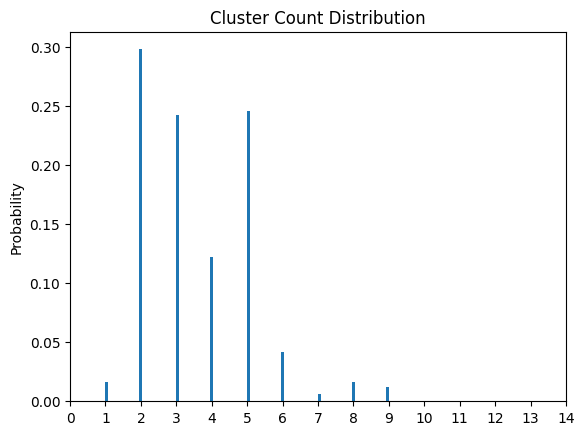

In [4]:
# cluster count distribution
ax = dist.marginalize(lambda cdist: len(cdist)).plot()
ax.set_xticks(np.arange(0, 15, 1))
ax.set_title("Cluster Count Distribution")

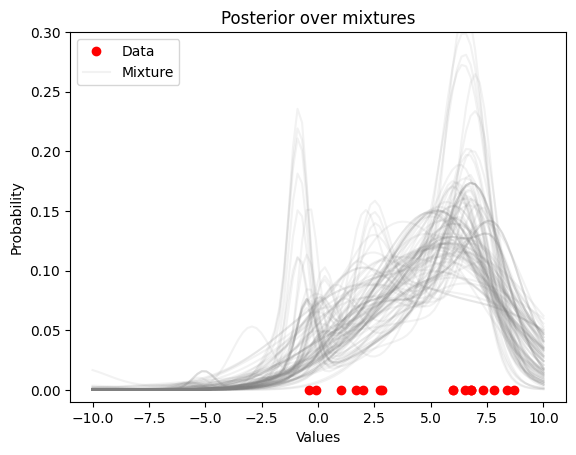

In [5]:
def plot_dp_mixture_sample(cdist, ax, **kws):
    cat_dist = {c: prob for c, (prob, _) in cdist.items()}
    for c, (prob, _) in cdist.items():
        for c_ in range(c + 1, max(cdist) + 1):
            cat_dist[c_] *= 1 - prob

    prob = np.zeros(100)
    for c, (_, (mu, sd)) in cdist.items():
        prob += stats.norm(mu, sd).pdf(np.linspace(-10, 10, 100)) * cat_dist[c]

    ax.plot(np.linspace(-10, 10, 100), prob, **kws)

def plot_posterior(data, dist):
    fig, ax = plt.subplots()
    ax.plot(data, [0] * len(data), "o", color="red", label='Data')
    for idx in range(100):
        cdist = dist.sample()
        plot_dp_mixture_sample(cdist, ax, alpha=.1, color="grey", label='Mixture' if idx == 0 else None)
    ax.set_title('Posterior over mixtures')
    ax.set_xlabel('Values')
    ax.set_ylabel('Probability')
    ax.set_ylim(-0.01, 0.3)
    ax.legend()

plot_posterior(dataset1, dist)

**Interpreting the cluster count:** The histogram shows the posterior distribution over the number of clusters. For this dataset, the model is most confident there are 2-3 clusters. This uncertainty is a feature, not a bug—it honestly represents our uncertainty about structure.

In [6]:
dataset2 = (2.0, 2.15, 1.98, 1.67, 1.54, -2.4, -2.1, 5.5, 6.8, 8.7, 6.0, 8.4, 9.1, 7.8, 7.3, 6.8, 6.5, 6.8)
dist = model(dataset2)

Text(0.5, 1.0, 'Cluster Count Distribution')

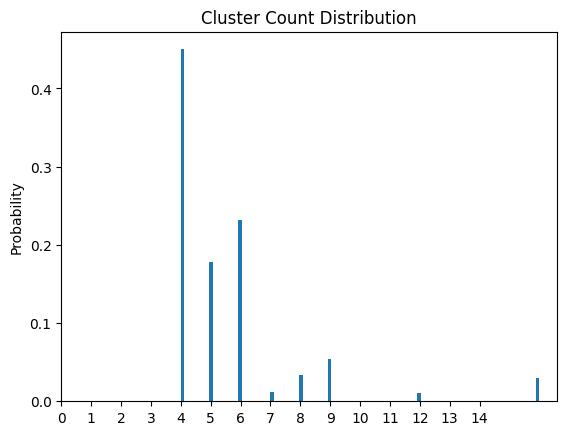

In [7]:
ax = dist.marginalize(lambda cdist: len(cdist)).plot()
ax.set_xticks(np.arange(0, 15, 1))
ax.set_title("Cluster Count Distribution")

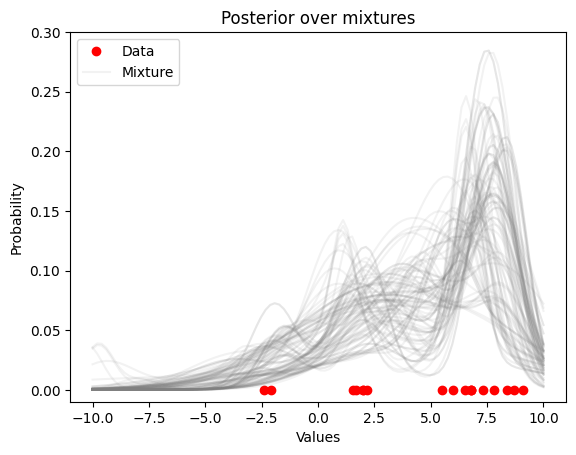

In [8]:
plot_posterior(dataset2, dist)

# Other constructions of the Dirichlet Process

## The Chinese Restaurant Process (CRP)

An equivalent way to generate Dirichlet Process samples is the **Chinese Restaurant Process**:

Imagine an infinitely large restaurant where customers arrive one at a time:

1. **First customer** sits at the first table
2. **Each subsequent customer** either:
   - Sits at an **existing table** with probability proportional to how many people are already there
   - Starts a **new table** with probability proportional to α

Mathematically, customer $n+1$ joins table $k$ with probability:
$$
P(\text{table } k) = \begin{cases} \frac{n_k}{n + \alpha} & \text{if table } k \text{ exists (has } n_k \text{ customers)} \\ \frac{\alpha}{n + \alpha} & \text{if starting a new table} \end{cases}
$$

This creates a **"rich get richer"** dynamic: popular tables attract more customers, but there's always some probability of starting something new.

The CRP and stick-breaking constructions produce the same distribution over cluster assignments!

Text(0.5, 0, 'Number of clusters')

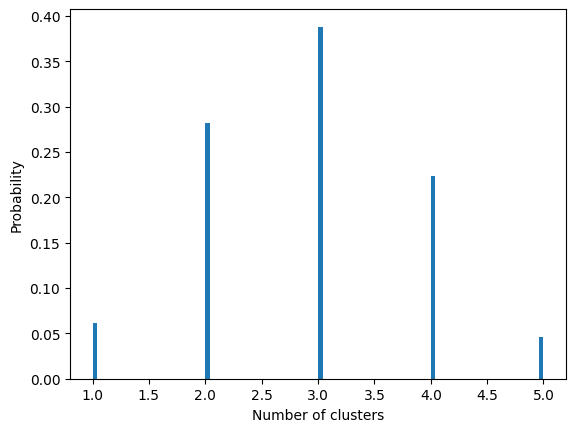

In [9]:
from flippy.distributions.builtin_dists import Categorical

def sample_category(concentration, c=0):
    if flip(break_stick(c, concentration)):
        return c
    return sample_category(concentration, c + 1)

@infer(method="SamplePrior", samples=10_000)
def dp_stick_breaking(n, concentration):
    cs = set()
    for _ in range(n):
        cs |= {sample_category(concentration)}
    return len(cs)

dp_stick_breaking(5, 2).plot()
plt.xlabel('Number of clusters')

Text(0.5, 0, 'Number of clusters')

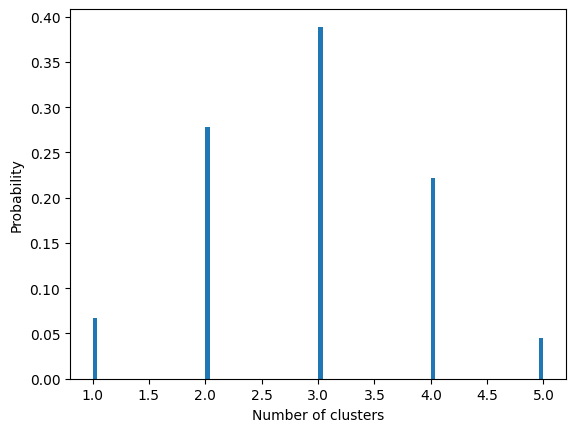

In [10]:
def increment(arr, idx):
    return arr[:idx] + [arr[idx] + 1] + arr[idx+1:]

@infer(method="Enumeration")
def dp_restaurant(n, concentration):
    counts = []
    for _ in range(n):
        c = Categorical(range(len(counts) + 1), weights=counts + [concentration]).sample()
        if c == len(counts): # sampled a new category
            counts += [0]
        counts = increment(counts, c)
    return len(counts)

dp_restaurant(5, 2).plot()
plt.xlabel('Number of clusters')

**Comparison:** Both constructions give the same distribution over the number of clusters. The stick-breaking construction is often easier to use for inference (it's a generative model), while the CRP is more intuitive and directly models cluster assignments.

# Summary

In this tutorial, you learned:
- **Dirichlet Processes** allow clustering with an unknown number of clusters
- The **stick-breaking construction** generates cluster probabilities by recursively breaking a stick
- The **Chinese Restaurant Process** provides an intuitive metaphor for the same process
- The **concentration parameter α** controls expected number of clusters

**Key applications:**
- Topic modeling (discovering an unknown number of topics in documents)
- Image segmentation (finding an unknown number of regions)
- Biological sequence clustering (discovering an unknown number of gene families)
- Customer segmentation (finding natural groupings without pre-specifying K)

**Extensions:**
- Hierarchical Dirichlet Processes (sharing clusters across groups)
- Dependent Dirichlet Processes (clusters that evolve over time)
- Pitman-Yor Processes (power-law behavior in cluster sizes)